In [2]:
from pathlib import Path
import sys

# Locate project root by searching for the project structure
current = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path for path in [current, *current.parents]
        if (
            (path / "src" / "lithology").is_dir()
            and (path / "data").is_dir()
        )
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate ml-lithology-classification project root."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")
print(f"Python executable: {sys.executable}")

Project root: C:\Users\Tammy\Desktop\ml-lithology-classification
Python executable: c:\Users\Tammy\anaconda3\python.exe


In [4]:
from src.lithology.data.las_loader import LASLoader
from src.lithology.preprocessing.quality_assurance import DataQualityAnalyzer

print("Project modules imported successfully.")

Project modules imported successfully.


In [7]:
# Load LAS data and run quality assessment
import pandas as pd
LAS_PATH = PROJECT_ROOT / "data" / "raw" / "1055867994.las"
loader = LASLoader(LAS_PATH)
loader.load()

df = loader.to_dataframe()

analyzer = DataQualityAnalyzer(
    dataframe=df,
    depth_column="DEPTH",
    null_values=[-999.25],
)

report = analyzer.generate_report()

for name, result in report.items():
    print(f"\n{'=' * 50}\n{name.upper()}\n{'=' * 50}")
    if isinstance(result, pd.DataFrame):
        display(result)
    else:
        print(result)

analyzer.export_report(
    PROJECT_ROOT / "outputs" / "reports" / "data_quality"
)


DATASET_SHAPE
(8682, 15)

MISSING_VALUES


,missing_count,missing_percentage
GR,88,1.013591
CNPOR,80,0.921447
RHOB,52,0.598940
RHOC,52,0.598940
DCAL,50,0.575904
DPOR,50,0.575904
PE,50,0.575904
SP,20,0.230362
RILD,10,0.115181
TBHV,5,0.057590



DUPLICATE_RECORDS
0

DUPLICATE_DEPTHS


,DEPTH,GR,TBHV,ABHV,RXORT,SP,RILD,RILM,RLL3,DCAL,RHOB,RHOC,DPOR,PE,CNPOR



INVALID_VALUES


,non_finite,null_sentinels
GR,88,0
TBHV,5,0
ABHV,5,0
RXORT,5,0
SP,20,0
RILD,10,0
RILM,4,0
RLL3,5,0
DCAL,50,0
RHOB,52,0


... (3 outputs left out)

,curve,unique_values,standard_deviation,is_constant,is_near_constant
0,GR,8552,26.114934,False,False
1,TBHV,8632,3877.846363,False,False
2,ABHV,8632,3687.023050,False,False
3,RXORT,8612,66.968767,False,False
4,SP,8628,50.548083,False,False
5,RILD,8003,14410.705461,False,False
6,RILM,7680,21701.336569,False,False
7,RLL3,8006,140.231154,False,False
8,DCAL,4951,10.885369,False,False
9,RHOB,6231,0.483337,False,False



DEPTH_CONTINUITY
{'minimum_depth': 0.0, 'maximum_depth': 4340.5, 'median_step': 0.5, 'mean_step': 0.5, 'minimum_step': 0.5, 'maximum_step': 0.5, 'non_increasing_steps': 0}

STATISTICS


,count,mean,std,min,25%,50%,75%,max
DEPTH,8682.0,2170.250000,1253.210926,0.0000,1085.125000,2170.25000,3255.375000,4340.5000
GR,8594.0,67.429696,26.114934,13.5921,48.399300,66.56070,82.233200,349.7787
TBHV,8677.0,3573.276772,3877.846363,0.0000,358.118400,1057.08890,6727.399900,12230.2520
ABHV,8677.0,3219.119842,3687.023050,0.0000,182.901000,702.94180,6194.322800,11518.1631
RXORT,8677.0,-0.954755,66.968767,-345.3154,-22.713300,-10.66930,-1.738600,385.7625
SP,8662.0,2.126571,50.548083,-178.5555,-26.085250,-4.96485,13.102800,232.6091
RILD,8672.0,2129.504725,14410.705461,0.2948,1.661825,2.81745,6.987750,100000.0000
RILM,8678.0,4962.487081,21701.336569,0.4417,1.471900,2.42775,5.498475,100000.0000
RLL3,8677.0,21.924849,140.231154,0.1653,2.142100,3.66550,7.768100,2024.9390
DCAL,8632.0,20.026798,10.885369,6.1953,8.597150,30.45515,30.487700,59.6927


WindowsPath('C:/Users/Tammy/Desktop/ml-lithology-classification/outputs/reports/data_quality')

In [10]:
from src.lithology.preprocessing.cleaner import DataCleaner

print("Starting preprocessing...")

cleaner = DataCleaner(df, depth_column="DEPTH")

cleaned_df = cleaner.run()

print("Original shape:", df.shape)
print("Cleaned shape:", cleaned_df.shape)
print(cleaner.missing_value_report())

output_path = PROJECT_ROOT / "data" / "interim" / "cleaned_well_logs.csv"
cleaned_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Starting preprocessing...
Original shape: (8682, 15)
Cleaned shape: (8682, 15)
       missing_count  missing_percentage
GR                88            1.013591
CNPOR             80            0.921447
RHOB              52            0.598940
RHOC              52            0.598940
DCAL              50            0.575904
DPOR              50            0.575904
PE                50            0.575904
SP                20            0.230362
RILD              10            0.115181
TBHV               5            0.057590
ABHV               5            0.057590
RXORT              5            0.057590
RLL3               5            0.057590
RILM               4            0.046072
DEPTH              0            0.000000
Saved: C:\Users\Tammy\Desktop\ml-lithology-classification\data\interim\cleaned_well_logs.csv


In [11]:
from src.lithology.features.engineering import PetrophysicalFeatureEngineer

engineer = PetrophysicalFeatureEngineer(cleaned_df)

featured_df = engineer.transform(
    vshale_method="pre_tertiary"
)

print("Feature dataset:", featured_df.shape)
display(featured_df.head())

featured_df.to_csv(
    PROJECT_ROOT / "data" / "processed" / "featured_well_logs.csv",
    index=False
)

Feature dataset: (8682, 19)


,DEPTH,GR,TBHV,ABHV,RXORT,SP,RILD,RILM,RLL3,DCAL,RHOB,RHOC,DPOR,PE,CNPOR,IGR,VSH,POROSITY_SEPARATION,RESISTIVITY_RATIO
0,0.0,245.6953,12230.2520,11518.1631,-345.3154,163.6230,0.2948,NaN,2024.8938,30.4889,0.7559,-0.3863,114.2760,22.3444,-3.4847,1.0,0.99,-117.7607,NaN
1,0.5,200.0675,12225.1807,11513.2568,-257.3493,202.5019,2.6945,NaN,1949.4741,30.4901,0.9319,-0.2293,103.9801,24.3403,-4.3065,1.0,0.99,-108.2866,NaN
2,1.0,184.8419,12222.6465,11510.8047,169.6684,222.2285,100000.0000,NaN,1302.5526,30.4859,1.0468,-0.1111,97.2641,26.6441,-5.0878,1.0,0.99,-102.3519,NaN
3,1.5,168.5336,12220.1123,11508.3525,177.9196,232.6091,100000.0000,NaN,1054.6669,30.4842,1.1516,0.0062,91.1353,28.3514,-5.5941,1.0,0.99,-96.7294,NaN
4,2.0,138.1998,12217.5781,11505.9014,155.8267,229.0952,100000.0000,4.652,1856.0620,30.4833,1.2619,0.1097,84.6817,28.7214,-5.9635,1.0,0.99,-90.6452,21496.130696


In [12]:
columns = [
    "GR", "RHOB", "DPOR", "CNPOR",
    "RILD", "RILM", "SP", "PE"
]

display(featured_df[columns].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
GR,8594.0,67.429696,26.114934,13.5921,23.526953,30.180965,48.399300,66.56070,82.233200,109.307015,135.105256,349.7787
RHOB,8630.0,2.078982,0.483337,0.7559,1.127387,1.234190,1.681050,2.22295,2.507575,2.636055,2.688884,2.9301
DPOR,8632.0,50.471650,891.729137,-12.8720,1.265228,4.325280,11.840725,28.51605,60.209550,86.339190,92.589664,58594.1523
CNPOR,8602.0,22.142943,8.979647,-6.4324,-1.783353,5.182210,16.256275,23.19100,28.056675,35.845855,41.219737,49.4301
RILD,8672.0,2129.504725,14410.705461,0.2948,0.661930,0.872265,1.661825,2.81745,6.987750,31.702010,100000.000000,100000.0000
RILM,8678.0,4962.487081,21701.336569,0.4417,0.622231,0.780570,1.471900,2.42775,5.498475,551.435695,100000.000000,100000.0000
SP,8662.0,2.126571,50.548083,-178.5555,-80.203538,-57.071400,-26.085250,-4.96485,13.102800,78.403095,183.642304,232.6091
PE,8632.0,4.579094,1.357339,3.0340,3.232055,3.383710,3.711400,4.73315,4.977300,5.685885,10.740807,28.7214


In [13]:
for col in ["DPOR", "RHOB", "RILD", "RILM", "PE"]:
    print(f"\n{col} — Extreme readings")
    display(
        featured_df.nlargest(5, col)[["DEPTH", col]]
    )


DPOR — Extreme readings


,DEPTH,DPOR
8630,4315.0,58594.1523
8631,4315.5,58594.1523
0,0.0,114.2760
1,0.5,103.9801
2,1.0,97.2641



RHOB — Extreme readings


,DEPTH,RHOB
4706,2353.0,2.9301
4707,2353.5,2.9274
4708,2354.0,2.9178
4705,2352.5,2.9106
4709,2354.5,2.9093



RILD — Extreme readings


,DEPTH,RILD
2,1.0,100000.0
3,1.5,100000.0
4,2.0,100000.0
5,2.5,100000.0
6,3.0,100000.0



RILM — Extreme readings


,DEPTH,RILM
10,5.0,100000.0
11,5.5,100000.0
12,6.0,100000.0
13,6.5,100000.0
14,7.0,100000.0



PE — Extreme readings


,DEPTH,PE
4,2.0,28.7214
3,1.5,28.3514
5,2.5,27.5726
2,1.0,26.6441
6,3.0,24.6974


In [14]:
for col in ["DPOR", "RHOB", "CNPOR", "PE"]:
    print(f"\n{col} — Lowest readings")
    display(
        featured_df.nsmallest(5, col)[["DEPTH", col]]
    )


DPOR — Lowest readings


,DEPTH,DPOR
4706,2353.0,-12.8720
4707,2353.5,-12.7116
4708,2354.0,-12.1536
4705,2352.5,-11.7293
4709,2354.5,-11.6551



RHOB — Lowest readings


,DEPTH,RHOB
0,0.0,0.7559
1,0.5,0.9319
2,1.0,1.0468
1852,926.0,1.0858
1853,926.5,1.0874



CNPOR — Lowest readings


,DEPTH,CNPOR
6,3.0,-6.4324
7,3.5,-6.3958
5,2.5,-6.2541
8,4.0,-6.0216
4,2.0,-5.9635



PE — Lowest readings


,DEPTH,PE
8627,4313.5,3.0340
8628,4314.0,3.0358
8626,4313.0,3.0388
8625,4312.5,3.0507
8624,4312.0,3.0661


In [20]:
import importlib

import src.lithology.visualization.well_logs as well_logs

importlib.reload(well_logs)

WellLogVisualizer = well_logs.WellLogVisualizer

print([
    method for method in dir(WellLogVisualizer)
    if method.startswith("plot_")
])

['plot_lithology_tracks']


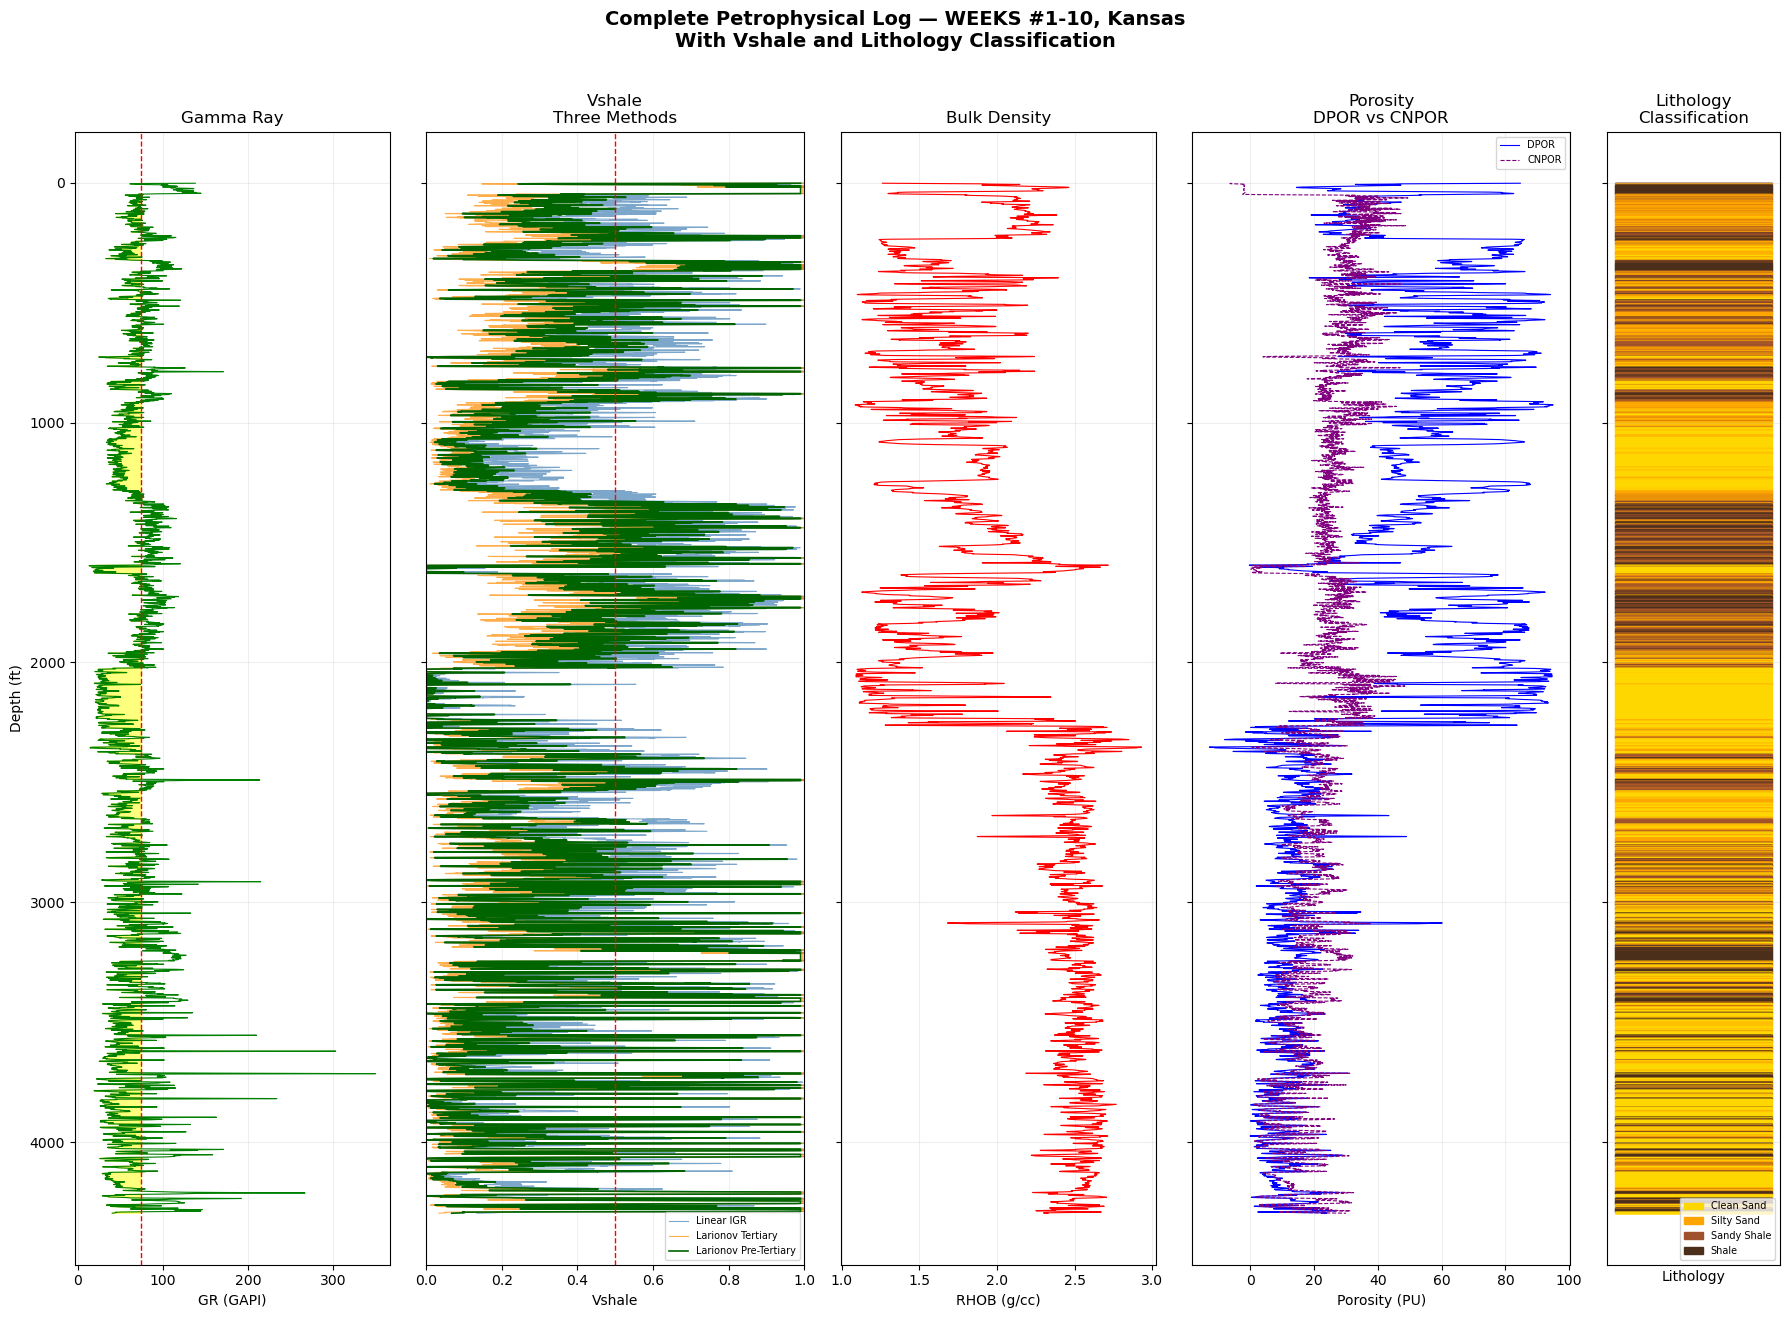

Project root: C:\Users\Tammy\Desktop\ml-lithology-classification
Dataset loaded: C:\Users\Tammy\Desktop\ml-lithology-classification\data\processed\weeks1_10_processed.csv
Figure saved: C:\Users\Tammy\Desktop\ml-lithology-classification\outputs\figures\lithology_tracks.png


In [21]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Locate project root, even when notebook runs from /notebooks
current = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path for path in [current, *current.parents]
        if (path / "src" / "lithology").is_dir()
        and (path / "data" / "processed").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate project root.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.lithology.visualization.well_logs import WellLogVisualizer

DATA_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "weeks1_10_processed.csv"
)

df = pd.read_csv(DATA_PATH)

visualizer = WellLogVisualizer(df)

fig, axes = visualizer.plot_lithology_tracks(
    figsize=(18, 13)
)

OUTPUT_PATH = PROJECT_ROOT / "outputs" / "figures" / "lithology_tracks.png"
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(OUTPUT_PATH, dpi=300, bbox_inches="tight")

plt.show()

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset loaded: {DATA_PATH}")
print(f"Figure saved: {OUTPUT_PATH}")